In [1]:
###################### Convert from csv to shapefile #######


from datetime import datetime, timedelta
import os
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import requests
import sys
import geopandas as gpd
import pandas as pd
from shapely.geometry import MultiPoint
from shapely.geometry import Point
import fiona
import contextily as ctx
import simplekml
from zipfile import ZipFile
from fastkml import kml
from osgeo import gdal, ogr

In [7]:
### converting from kml to shp ####
kml_file = '/Users/bz294/Documents/WhiteZone/Points/KML/2013/pt1_2013.kml'
driver = ogr.GetDriverByName('KML')
dataSource = driver.Open(kml_file, 0)  # 0 means read-only

# Step 2: Convert KML to shapefile
output_shapefile = '/Users/bz294/Documents/WhiteZone/Points/KML/2013/class2013.shp'
driver = ogr.GetDriverByName('ESRI Shapefile')
output = driver.CreateDataSource(output_shapefile)

for layer in dataSource:
    # Create a new layer in the shapefile
    output_layer = output.CreateLayer(layer.GetName(), geom_type=layer.GetGeomType())

    # Copy the layer's fields to the new layer in the shapefile
    output_layer.CreateFields(layer.schema)

    # Step 4: Loop through features in the KML layer and copy them to the shapefile
    for feature in layer:
        output_layer.CreateFeature(feature)

gdf = gpd.read_file(output_shapefile)

# Step 6: Add Latitude and Longitude (assuming Point geometry)
gdf['Latitude'] = gdf.geometry.apply(lambda x: x.y if x else None)
gdf['Longitude'] = gdf.geometry.apply(lambda x: x.x if x else None)

# Step 7: Save the modified GeoDataFrame as a new shapefile
gdf.to_file('/Users/bz294/Documents/WhiteZone/Points/KML/2013/class2013_atri.shp')

# Step 8: Print the dataframe (optional)
print(gdf.head())

Warning 6: Normalized/laundered field name: 'Description' to 'Descriptio'
Warning 6: Normalized/laundered field name: 'Description' to 'Descriptio'


ValueError: GeoDataFrame contains multiple geometry columns but GeoDataFrame.to_file supports only a single geometry column. Use a GeoDataFrame.to_parquet or GeoDataFrame.to_feather, drop additional geometry columns or convert them to a supported format like a well-known text (WKT) using `GeoSeries.to_wkt()`.

In [8]:
gdf

,Name,Descriptio,geometry,Latitude,Longitude


In [11]:
########### Read kmz and convert to shapefile #################
kmz_file = "/Users/bz294/Documents/WhiteZone/Points/KML/2023/points_revised_2023_2.kmz"

# Extract the KML file
with ZipFile(kmz_file, 'r') as kmz:
    kmz.extractall("/Users/bz294/Documents/WhiteZone/Points/KML/2023/extracted_kml2")  # Creates a directory with extracted content


#gdf = gpd.read_file(kml_file)
# #gdf.to_file("/Users/bz294/Documents/WhiteZone/Points/KML/kml1.geojson", driver="GeoJSON")
# gdf = gpd.read_file("/Users/bz294/Documents/WhiteZone/Points/kml2.geojson")
# gdf.to_file("region2.shp", driver="ESRI Shapefile")
#

In [21]:
driver = ogr.GetDriverByName("KML")
datasource = driver.Open(kml_file)


if datasource is None:
    print("Could not open KML file.")
    exit()

shapefile_driver = ogr.GetDriverByName("ESRI Shapefile")

# Create the new shapefile and copy the KML layer(s)
shapefile = shapefile_driver.CreateDataSource(shapefile_path)
for i in range(datasource.GetLayerCount()):
    layer = datasource.GetLayerByIndex(i)
    shapefile.CopyLayer(layer, layer.GetName())

Warning 6: Normalized/laundered field name: 'Description' to 'Descriptio'


The shapefile contains 0 features.


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_86668/3644741043.py:12: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  gdf.plot(ax=ax, color='blue', edgecolor='black', alpha=0.5)


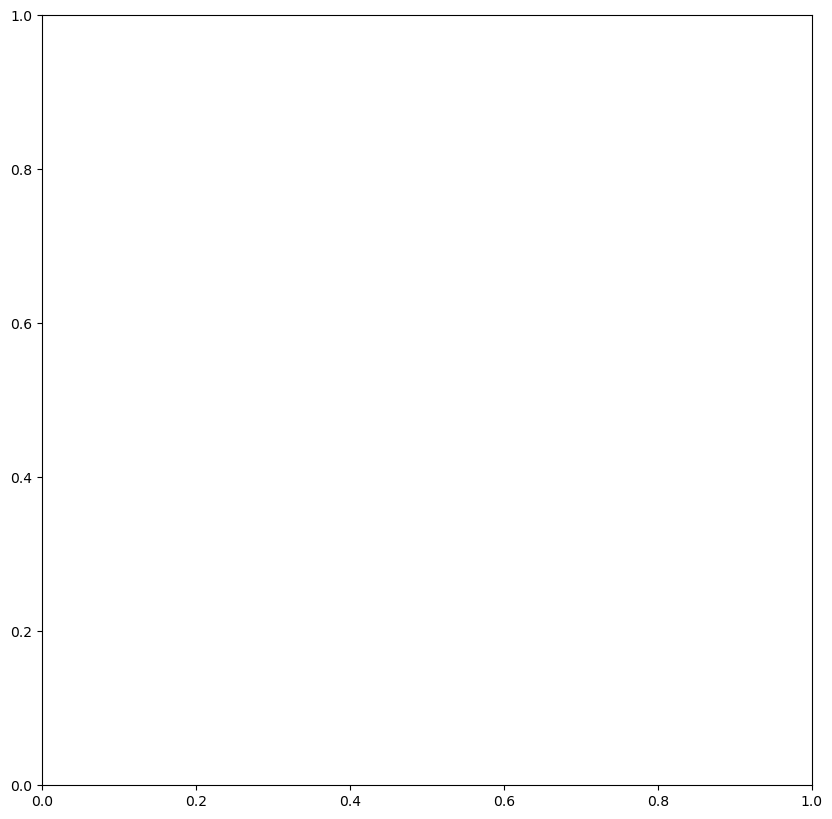

In [17]:
gdf = gpd.read_file('/Users/bz294/Documents/WhiteZone/Points/KML/shapefile2.shp')

# Ensure the GeoDataFrame is in Web Mercator projection (EPSG:3857) for compatibility with contextily
if gdf.crs != "EPSG:3857":
    gdf = gdf.to_crs("EPSG:3857")

# Plot the shapefile with a basemap
fig, ax = plt.subplots(figsize=(10, 10))
gdf.plot(ax=ax, color='blue', edgecolor='black', alpha=0.5)

# Add a basemap from contextily
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik) 

plt.show()

In [9]:
with ZipFile(kmz_file, 'r') as kmz:
    with kmz.open('doc.kml', 'r') as kml_file:
        kml_content = kml_file.read()

# Parse the KML
k = kml.KML()
kml_content = kml_content.replace('<?xml version="1.0" encoding="UTF-8"?>', '')

# Extract features and convert to GeoDataFrame
features = []
for feature in list(k.features()):
    for placemark in feature.features():
        geometry = shape(placemark.geometry)
        features.append({"geometry": geometry, "properties": placemark.extended_data})

gdf = gpd.GeoDataFrame.from_records(features)

TypeError: a bytes-like object is required, not 'str'

In [ ]:
path = '/Users/bz294/Documents/WhiteZone/Points/'
file1 = 'cp01.csv'
file2 = 'cp02.csv'
df1 = pd.read_csv(path + file1)
df2 = pd.read_csv(path + file2)


In [ ]:
df2['geometry'] = df2.apply(lambda row: Point(row['Longitude'], row['Latitude']), axis=1)
gdf = gpd.GeoDataFrame(df2, geometry='geometry')

# Set the coordinate reference system to WGS84
gdf.set_crs(epsg=4326, inplace=True)

# Save the GeoDataFrame as a shapefile
gdf.to_file("points_shapefile2.shp")


print("Shapefile created successfully!")

In [ ]:
pwd

In [ ]:
gdf = gpd.read_file("points_shapefile.shp")

# Initialize a KML object
kml = simplekml.Kml()

# Iterate through each row in the GeoDataFrame
for _, row in gdf.iterrows():
    # Convert each geometry to KML
    if row.geometry.geom_type == 'Point':
        kml.newpoint(coords=[(row.geometry.x, row.geometry.y)])
    elif row.geometry.geom_type == 'LineString':
        kml.newlinestring(coords=list(row.geometry.coords))
    elif row.geometry.geom_type == 'Polygon':
        kml.newpolygon(outerboundaryis=list(row.geometry.exterior.coords))

# Save the KML file
kml.save("points.kml")

In [ ]:
gdf

In [ ]:
### converting from shp to kml ####

gdf = gpd.read_file("points_shapefile.shp")

# Initialize KML object
kml = simplekml.Kml()

# Define colors for each 'Description' value
colors = {
    'VZ': 'ff00ff00',  # Green in KML color format (aabbggrr)
    'WZ': 'ff0000ff',  # Red
    'TZ': 'ff00ffff'   # Yellow
}

# Iterate over each row in the GeoDataFrame
for _, row in gdf.iterrows():
    desc_value = row['Descriptio']
    color = colors.get(desc_value, 'ff000000')  # Default to black if no match
    print(desc_value)
    print(color)
    # Create a KML placemark
    if row.geometry.geom_type == 'Point':
        pnt = kml.newpoint(coords=[(row.geometry.x, row.geometry.y)])
        pnt.style.iconstyle.color = color
    elif row.geometry.geom_type == 'LineString':
        line = kml.newlinestring(coords=list(row.geometry.coords))
        line.style.linestyle.color = color
    elif row.geometry.geom_type == 'Polygon':
        poly = kml.newpolygon(outerboundaryis=list(row.geometry.exterior.coords))
        poly.style.polystyle.color = color

    # Add description for each placemark
    pnt.description = row['Descriptio']

# Save the KML
kml.save("points_styled.kml")

In [ ]:
shapefile_path = "points_shapefile.shp"
gdf = gpd.read_file(shapefile_path)
gdf = gdf.to_crs(epsg=4326)

fig, ax = plt.subplots(figsize=(10, 10))
gdf.plot(ax=ax, color="blue", edgecolor="black", alpha=0.6)

# Add basemap from contextily
#ctx.add_basemap(ax, source=ctx.providers.Stamen.Terrain)

plt.show()

In [ ]:
pwd